# State of the art: lifetime PD by survival, competing risks and macro satellites

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 05 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- place the three lifetime-PD rungs of C06 (Kaplan-Meier, a discrete-time hazard with macro covariates, a Cox model) in the survival methods the research found, and say which methods the product does not run;
- show why the discrete-time logit and the Cox model give nearly the same coefficients when the period hazard is small;
- check the signs of the macro coefficients against economic expectation, as a validator must, and read what a wrong sign does to a scenario ECL;
- compare the three rungs on the same data by discrimination, integrated Brier score and calibration of the cumulative PD, pooled and for the crisis vintage;
- measure what treating prepayment as censoring costs against a competing-risks view, and read the macro satellite's factor paths with their reversion to the long run.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C06 at the reporting date 2008-12-31: the SBA 7(a) small-business loans (U.S. Government Works, licence class `mirror-allowed`) and the Federal Reserve 2026 scenario shapes (mirror-allowed). Two committed files are read.

- `data/derived/C06/models-rd-2008-12.json`: the fit of the three rungs (`fit.ladder`: the coefficients and standard errors, the baseline of the Kaplan-Meier and Cox rungs), the macro scaler of the hazard rung (`model[].details.macro_scaler`), the one-factor conversion (`fit.pit`: the history of the systematic factor and the satellite) and the scenario definitions with their factor paths (`fit.scenario_definitions`).
- `data/derived/C06/rd-2008-12.json`: `outputs.rung_comparison` (discrimination, integrated Brier score and 12-month calibration gap of each rung), and the `tests` rows of the lifetime back-test by origination cohort and rung, whose `extras` keep the gap of each horizon.

The three rungs were fitted by the pipeline (`data-pipeline/pipeline/cases/c06/ladder.py`, with `statsmodels`) on the loans known at the reporting date; the raw loan file is not committed, so this notebook **reads the fits and the tests, and does not refit**. Everything recomputed below is arithmetic on committed numbers or an engine call on them.

In [2]:
# Load the model file and the reporting-date artifact and list the three rungs
from riskvalidation.provisions import term_structure as tsm

ROOT = Path("../../..").resolve()
LANG = "en"
models = json.loads((ROOT / "data" / "derived" / "C06" / "models-rd-2008-12.json").read_text(encoding="utf-8"))
case = json.loads((ROOT / "data" / "derived" / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
fit = models["fit"]
ladder = {r["rung_id"]: r for r in fit["ladder"]}

for m_ in models["model"]:
    print(f"{m_['id']:7s} {m_['rung']:22s} | {m_['engine']} {m_['engine_version']} | loans: {int(m_['parameters']['n_loans']['value'])} | defaults: {int(m_['parameters']['n_defaults']['value'])}")
print("training cut-off:", {k: v["training_cutoff"] for k, v in ladder.items()})
print("artifact baked by engine:", case["provenance"]["riskvalidation_version"], "| installed engine:", md.version("riskvalidation"))

L0-km   kaplan-meier           | statsmodels 0.15.0 | loans: 871618 | defaults: 74139
L1-dth  discrete-time-hazard   | statsmodels 0.15.0 | loans: 871618 | defaults: 74139
L2-cox  cox                    | statsmodels 0.15.0 | loans: 871618 | defaults: 74139
training cut-off: {'L0-km': '2008-12-31', 'L1-dth': '2008-12-31', 'L2-cox': '2008-12-31'}
artifact baked by engine: 0.5.0 | installed engine: 0.8.1


## Method

All three rungs model the time from the reporting date to default, with prepayment as censoring, and give the cumulative PD $F(t)$ that notebook 01 turns into an ECL. They differ in how they let the hazard depend on the loan and on the macroeconomy.

**L0, Kaplan-Meier.** One pooled curve by loan age. The product-limit estimator of the survival is $\hat S(t) = \prod_{t_i \le t}\bigl(1 - d_i/n_i\bigr)$, with $d_i$ the defaults and $n_i$ the loans at risk at age $t_i$. It has no covariates and no macroeconomy, so its ranking is only the age ranking.

**L1, discrete-time hazard with macro covariates.** A logistic regression on loan-period records (Shumway, 2001; Botha and Verster, 2025):

$$\mathrm{logit}\,h_i(t) = \alpha(a_{it}) + \boldsymbol\beta^\top \mathbf{x}_i + \boldsymbol\gamma^\top \mathbf{m}_{t-\ell}$$

with $\alpha$ a step function of loan age (age bands), $\mathbf{x}_i$ the loan covariates (size, term, sector, revolving) and $\mathbf{m}_{t-\ell}$ the macro variables lagged $\ell = 1$ quarter, standardised. It is the rung that carries the scenarios.

**L2, Cox proportional hazards** (Cox, 1972): $h_i(t) = h_0(t)\exp(\boldsymbol\beta^\top \mathbf{x}_i)$, with loan age as the time scale and Breslow ties. The `statsmodels` implementation the pipeline uses has no time-varying covariates, so this rung has **no macroeconomy** and cannot carry a scenario.

For a small period hazard $h$, $\mathrm{logit}\,h = \log\bigl(h/(1-h)\bigr) \approx \log h$, so the coefficients of L1 and L2 on the common covariates should agree. The macroeconomy enters the term structure of L1 only.

**The validation of a rung** is the lifetime back-test of notebook 05 and the rung comparison: Harrell's concordance (the probability that of two loans the one with the shorter survival has the higher predicted risk, ties as one half), the integrated Brier score of the survival prediction and the 12-month calibration gap between the predicted and the observed cumulative PD. The one-factor view (BCBS 2005; Gordy 2003) links the macroeconomy to the PD through a systematic factor $z$ that a satellite regresses on macro variables; the weights on short-term forecasts decay to long-term values (ECB letter of 1 April 2020).

## State of the art

The research (dossiers 02 and 04) found the following methods for the term structure of default under IFRS 9. The last column says what the product does with each.

| Method | What it adds | Source | In Contraste |
|---|---|---|---|
| Kaplan-Meier and vintage curves | the pooled and the cohort cumulative default, with censoring | Botha and Verster 2025 | rung L0, read here |
| Discrete-time hazard (person-period logit) with macro covariates | lifetime PD under a macro scenario, with a lagged macro vector | Shumway 2001; Botha and Verster 2025 | rung L1, read here |
| Cox proportional hazards, with or without time-varying covariates | covariate effects without a baseline assumption; time-varying macro | Cox 1972 | rung L2 (no time-varying covariates), read here |
| Competing risks, cause-specific or Fine-Gray | default incidence when prepayment is a competing exit | Fine and Gray 1999; Botha and Verster 2025 | the engine's `competing_risks`; C06 treats prepayment as censoring (finding `F-PREPAYMENT`) |
| Age-period-cohort decomposition | lifecycle, vintage quality and environment in one logit | Breeden 2016 | not run |
| Multistate and roll-rate models | transitions between delinquency states with macro inputs | Botha, Verster and Breedt 2025 | not run |
| Mixture cure, survival forests, deep survival | a cured fraction; non-linear effects | the research, dossier 04 (rungs S4 to S6) | not run |
| Macro satellite with mean reversion | scenario paths of a systematic factor that revert to the long run | ECB letter of 1 April 2020; Botha and Verster 2025 | the one-factor satellite of `fit.pit`, read here |

The packages those last rungs need (`lifelines`, `scikit-survival`, `pycox`) are not pins of the pipeline or of the notebook environment, so it is **UNVERIFIED** that Contraste runs any of them: this notebook compares only the three rungs that C06 committed. The research's validation metrics for survival models (Harrell and Uno concordance, time-dependent AUC, integrated Brier score, and calibration of the cumulative PD by decile at fixed horizons against the Kaplan-Meier or Aalen-Johansen estimate) are the ones the rung comparison uses; the committed rung comparison reports the concordance, the integrated Brier score and the 12-month calibration gap.

### Step 1: the coefficients of L1 and L2 on the common covariates

Both rungs have the loan covariates: three size bands, three term bands, eleven sector groups and the revolving flag. The cell lines up the 18 coefficients that both fit, prints a few, and measures how close the two sets are: the largest absolute difference and the correlation. L1's are on the logit scale and L2's on the log-hazard scale, and they are expected to agree when the hazard per period is small.

In [3]:
# Align the coefficients that the discrete-time hazard and the Cox model share and compare them
dth = {c["name"]: c for c in ladder["L1-dth"]["coefficients"]}
cox = {c["name"]: c for c in ladder["L2-cox"]["coefficients"]}
common = [name for name in cox if name in dth]
a = np.array([dth[n]["estimate"] for n in common])
b = np.array([cox[n]["estimate"] for n in common])
print("common covariates:", len(common), "| only in the hazard rung (age bands, macro, constant):", len(dth) - len(common))
for n in ("term_over_240", "term_61_120", "revolver", "sector_accommodation-food", "size_over_350k"):
    print(f"{n:28s} L1: {dth[n]['estimate']:+.4f} | L2: {cox[n]['estimate']:+.4f} | difference: {dth[n]['estimate'] - cox[n]['estimate']:+.4f}")
print("largest absolute difference:", round(float(np.abs(a - b).max()), 4), "| correlation:", round(float(np.corrcoef(a, b)[0, 1]), 5))
print("largest difference in units of the standard error of L1:", round(float(np.max(np.abs(a - b) / np.array([dth[n]["std_error"] for n in common]))), 2))

common covariates: 18 | only in the hazard rung (age bands, macro, constant): 12
term_over_240                L1: -2.4475 | L2: -2.4413 | difference: -0.0062
term_61_120                  L1: -1.0719 | L2: -1.0559 | difference: -0.0159
revolver                     L1: +0.5083 | L2: +0.5436 | difference: -0.0353
sector_accommodation-food    L1: +0.6726 | L2: +0.6336 | difference: +0.0389
size_over_350k               L1: +0.0641 | L2: +0.0629 | difference: +0.0012
largest absolute difference: 0.0389 | correlation: 0.9998
largest difference in units of the standard error of L1: 3.2


### Step 2: the macro coefficients and their signs

Only L1 has macro covariates, standardised with the mean and standard deviation of the macro scaler. A validator checks each sign against economic expectation: a higher unemployment rate and a higher prime rate should raise the hazard, higher real GDP growth should lower it (IFRS 9 B5.5.52 asks that changes in the ECL be directionally consistent with the data; BCBS d350 36(d) asks for the factors to be backtested). The expectations are the **stated** ones of this lesson. The cell prints, for each variable, the estimate, its standard error, the $z$-statistic $\hat\gamma/\mathrm{se}$, the hazard ratio per standard deviation $e^{\hat\gamma}$ (on the odds scale) and whether the sign is the expected one.

In [4]:
# Read the macro coefficients of the hazard rung and check their signs against the stated expectation
EXPECTED_SIGN = {"unemployment_rate": +1, "real_gdp_growth": -1, "prime_rate": +1}  # stated expectation of the lesson
scaler = [m_ for m_ in models["model"] if m_["id"] == "L1-dth"][0]["details"]["macro_scaler"]
for name, sign in EXPECTED_SIGN.items():
    c = dth[name]
    z = c["estimate"] / c["std_error"]
    ok = np.sign(c["estimate"]) == sign
    print(f"{name:18s} mean and sd of the scaler: {scaler[name][0]:.3f} {scaler[name][1]:.3f} | estimate: {c['estimate']:+.4f} | std. error: {c['std_error']:.4f} | z: {z:+.2f} | exp: {np.exp(c['estimate']):.3f} | expected sign: {ok}")
print("the finding that the artifact commits:", [f["title"][LANG] for f in case["findings"] if f["id"] == "F-SCENARIO-ORDER"][0])

unemployment_rate  mean and sd of the scaler: 5.441 0.966 | estimate: -0.0534 | std. error: 0.0089 | z: -5.99 | exp: 0.948 | expected sign: False
real_gdp_growth    mean and sd of the scaler: 2.873 2.239 | estimate: -0.1920 | std. error: 0.0039 | z: -49.11 | exp: 0.825 | expected sign: True
prime_rate         mean and sd of the scaler: 7.147 1.685 | estimate: +0.1138 | std. error: 0.0060 | z: +18.86 | exp: 1.120 | expected sign: True
the finding that the artifact commits: The severely adverse scenario gives a lower ECL than the baseline: the hazard's macro sensitivities have the wrong sign at this date


### Step 3: the three rungs on the same data

The rung comparison of the artifact reports, for each rung, the concordance index, the integrated Brier score and the gap between the predicted and the observed cumulative PD at 12 months. The Kaplan-Meier rung is one pooled curve by age, so it reports no concordance (its ranking is the age ranking) and the artifact gives the reason in English only. The cell prints the table and the rung that wins each column.

In [5]:
# Print the rung comparison and the winner of each column
comparison = {r["rung_id"]: r for r in case["outputs"]["rung_comparison"]}
print(f"{'':8s} {'c-index':>10s} {'integrated Brier':>18s} {'12-month gap':>22s}")
for rung, r in comparison.items():
    c_index = "-" if r["c_index"] is None else f"{r['c_index']:.4f}"
    print(f"{rung:8s} {c_index:>10s} {r['integrated_brier']:18.4f} {r['calibration_gap_12m']:22.4f}")
with_c = {k: r["c_index"] for k, r in comparison.items() if r["c_index"] is not None}
print("best concordance:", max(with_c, key=with_c.get), "| best integrated Brier:", min(comparison, key=lambda k: comparison[k]["integrated_brier"]), "| smallest 12-month gap:", min(comparison, key=lambda k: comparison[k]["calibration_gap_12m"]))
print("spread of the integrated Brier of the three rungs below 1e-3:", max(r["integrated_brier"] for r in comparison.values()) - min(r["integrated_brier"] for r in comparison.values()) < 0.001)

            c-index   integrated Brier           12-month gap
L0-km             -             0.0615                 0.0118
L1-dth       0.6106             0.0606                 0.0025
L2-cox       0.5903             0.0615                 0.0141
best concordance: L1-dth | best integrated Brier: L1-dth | smallest 12-month gap: L1-dth
spread of the integrated Brier of the three rungs below 1e-3: True


### Step 4: calibration of the cumulative PD, pooled and for the crisis vintage

The lifetime back-test rows keep, for each rung and cohort, the gap of each horizon, defined by the engine as $\mathrm{signed\_gap} = \mathrm{observed} - \mathrm{predicted}$. The observed cumulative PD is the same for the three rungs (a Kaplan-Meier estimate), and the artifact keeps it with the `L1-dth` prediction (`outputs.lifetime_backtest`), so the predicted curve of each rung is $\mathrm{predicted} = \mathrm{observed} - \mathrm{signed\_gap}$. The cell rebuilds the predicted curves for the pooled `all` cohort and for the 2007 vintage, checks the identity on L1 against the committed predictions, and prints the horizons at 12, 24 and 36 months. A positive signed gap means the model predicted less default than happened.

In [6]:
# Rebuild the predicted cumulative PD of each rung from the observed curve and the committed signed gaps
rows = case["outputs"]["lifetime_backtest"]["rows"]
tests = {(t["model_id"], t["segment"]): t for t in case["tests"] if t["test_id"] == "ifrs9.lifetime_pd_backtest"}
curves = {}
for cohort in ("all", "2007"):
    obs = np.array([r["observed_cumulative_pd"] for r in rows if r["origination_cohort"] == cohort])
    pred_l1 = np.array([r["predicted_cumulative_pd"] for r in rows if r["origination_cohort"] == cohort])
    months = np.array([r["months"] for r in rows if r["origination_cohort"] == cohort])
    predicted = {rung: obs - np.array(tests[(rung, cohort)]["extras"]["signed_gap"]) for rung in ("L0-km", "L1-dth", "L2-cox")}
    curves[cohort] = (months, obs, predicted)
    print("cohort", cohort, "| identity on L1 against the committed prediction:", bool(np.allclose(predicted["L1-dth"], pred_l1, atol=1e-8, rtol=0)))
    for k in (1, 3, 5):
        print("   month", int(months[k]), "| observed:", round(float(obs[k]), 4), "|", *[f"{rung}: {predicted[rung][k]:.4f}" for rung in predicted])
    print("   signed gap at 36 months:", {rung: round(float(obs[5] - predicted[rung][5]), 4) for rung in predicted})
    print("   rungs that under-predict at every horizon:", [rung for rung in predicted if bool(np.all(obs - predicted[rung] > 0))])

cohort all | identity on L1 against the committed prediction: True
   month 12 | observed: 0.0324 | L0-km: 0.0205 L1-dth: 0.0298 L2-cox: 0.0183
   month 24 | observed: 0.0804 | L0-km: 0.0438 L1-dth: 0.0637 L2-cox: 0.0416
   month 36 | observed: 0.1083 | L0-km: 0.0656 L1-dth: 0.0959 L2-cox: 0.0656
   signed gap at 36 months: {'L0-km': 0.0427, 'L1-dth': 0.0124, 'L2-cox': 0.0427}
   rungs that under-predict at every horizon: ['L0-km', 'L1-dth', 'L2-cox']
cohort 2007 | identity on L1 against the committed prediction: True
   month 12 | observed: 0.074 | L0-km: 0.0220 L1-dth: 0.0386 L2-cox: 0.0222
   month 24 | observed: 0.1696 | L0-km: 0.0496 L1-dth: 0.0837 L2-cox: 0.0533
   month 36 | observed: 0.2006 | L0-km: 0.0766 L1-dth: 0.1267 L2-cox: 0.0863
   signed gap at 36 months: {'L0-km': 0.124, 'L1-dth': 0.074, 'L2-cox': 0.1143}
   rungs that under-predict at every horizon: ['L0-km', 'L1-dth', 'L2-cox']


### Step 5: prepayment as censoring against a competing exit

C06 treats prepayment as censoring (finding `F-PREPAYMENT`): the cause-specific default hazard is the whole of the lifetime PD. With a competing exit the loans that prepay are no longer at risk, and the default incidence is $q^D(t) = S^{\mathrm{all}}(t-1)\,h^D(t)$ (`competing_risks`). The research notes that ignoring prepayment overstates the lifetime PD (Botha and Verster, 2025; IFRS 9 B5.5.51). To measure how much, the cell takes the Kaplan-Meier baseline of L0, converts it into period hazards with `from_cumulative`, adds a **stated** prepayment hazard per quarter (0, 0.5, 1 and 2%, lesson inputs) and compares the cumulative default incidence at 36 months with the censoring view.

In [7]:
# Add a stated prepayment hazard to the Kaplan-Meier baseline and compare the default incidence with the censoring view
base = ladder["L0-km"]["baseline"]
base_months = np.array(base["months"])
single = tsm.from_cumulative(np.array(base["cumulative_pd"]), base_months)
at_36 = int(np.flatnonzero(base_months == 36)[0])
print("censoring view, cumulative default at 36 months:", round(float(single.cumulative[at_36]), 5))
for prepay in (0.0, 0.005, 0.01, 0.02):
    c = tsm.competing_risks(single.hazard, np.full(single.hazard.shape, prepay), base_months)
    ratio = float(single.cumulative[at_36] / c.cumulative_default[at_36])
    print("prepayment hazard per quarter", prepay, "| default incidence at 36 months:", round(float(c.cumulative_default[at_36]), 5), "| censoring over competing:", round(ratio, 4), "| at 120 months:", round(float(single.cumulative[-1] / c.cumulative_default[-1]), 4))

censoring view, cumulative default at 36 months: 0.04394
prepayment hazard per quarter 0.0 | default incidence at 36 months: 0.04394 | censoring over competing: 1.0 | at 120 months: 1.0
prepayment hazard per quarter 0.005 | default incidence at 36 months: 0.04222 | censoring over competing: 1.0407 | at 120 months: 1.0924
prepayment hazard per quarter 0.01 | default incidence at 36 months: 0.04056 | censoring over competing: 1.0831 | at 120 months: 1.1915
prepayment hazard per quarter 0.02 | default incidence at 36 months: 0.03744 | censoring over competing: 1.1735 | at 120 months: 1.4114


### Step 6: the satellite and the factor paths

The one-factor conversion gives the systematic factor $z$ of each past quarter from the book's realised default rate (`fit.pit.z_hat`), and the scenario paths of $z$ from the default rate the hazard rung implies under each scenario (`fit.scenario_definitions[].z_path`). A negative $z$ is a bad year. The cell prints the satellite's coefficients with their signs against the same expectation as in step 2 (for the factor: unemployment and the prime rate push it down, growth pushes it up), the history of the factor, and the three scenario paths at a few horizons. The paths start at the same value and end at the same value: the scenarios converge to the long run, which is the mean reversion the ECB letter asks for.

In [8]:
# Read the satellite, the factor history and the three scenario paths of the factor
satellite = fit["pit"]["satellite"]
EXPECTED_FACTOR_SIGN = {"unemployment_rate": -1, "real_gdp_growth": +1, "prime_rate": -1}  # stated expectation of the lesson, for the factor
print("satellite intercept and autoregressive term:", round(satellite["intercept"], 4), satellite["ar1"])
for c in satellite["coefficients"]:
    print(f"{c['name']:18s} coefficient: {c['value']:+.4f} | expected sign for the factor: {np.sign(c['value']) == EXPECTED_FACTOR_SIGN[c['name']]}")
history = np.array([p["z"] for p in fit["pit"]["z_hat"]])
print("quarters of factor history:", history.size, "| mean and standard deviation:", round(float(history.mean()), 3), round(float(history.std()), 3), "| last value:", round(float(history[-1]), 3))
paths = {s["id"]: np.array([p["z"] for p in s["z_path"]]) for s in fit["scenario_definitions"]}
months_path = [p["months"] for p in fit["scenario_definitions"][0]["z_path"]]
for k in (0, 7, 13, 26, 39):
    print("month", months_path[k], "|", *[f"{sid}: {paths[sid][k]:+.3f}" for sid in paths])
print("same start and same end in the three scenarios:", bool(np.allclose([p[0] for p in paths.values()], paths["baseline"][0]) and np.allclose([p[-1] for p in paths.values()], paths["baseline"][-1])))
print("the baseline path lies below the severely adverse one at month 39:", bool(paths["baseline"][12] < paths["severely-adverse"][12]), "| month", months_path[12])

satellite intercept and autoregressive term: 13.3395 0.0
unemployment_rate  coefficient: -1.0554 | expected sign for the factor: True
real_gdp_growth    coefficient: +0.3289 | expected sign for the factor: True
prime_rate         coefficient: -1.4056 | expected sign for the factor: True
quarters of factor history: 63 | mean and standard deviation: -0.15 0.731 | last value: -1.8
month 3 | baseline: -1.432 adverse: -1.432 severely-adverse: -1.432
month 24 | baseline: -1.531 adverse: -1.351 severely-adverse: -1.351
month 42 | baseline: -1.205 adverse: -1.035 severely-adverse: -0.956
month 81 | baseline: -0.057 adverse: -0.057 severely-adverse: -0.057
month 120 | baseline: +0.879 adverse: +0.879 severely-adverse: +0.879
same start and same end in the three scenarios: True
the baseline path lies below the severely adverse one at month 39: True | month 39


### Step 7: the curves and the paths, drawn

The left panel draws the 2007 vintage, the one that originated just before the crisis: the observed cumulative PD and the predicted curve of each rung over the six horizons. The right panel draws the three scenario paths of the systematic factor over the 120 months: all start and end at the same point, and in between the baseline lies below the adverse and the severely adverse, which is the ordering that the committed finding `F-SCENARIO-ORDER` flags.

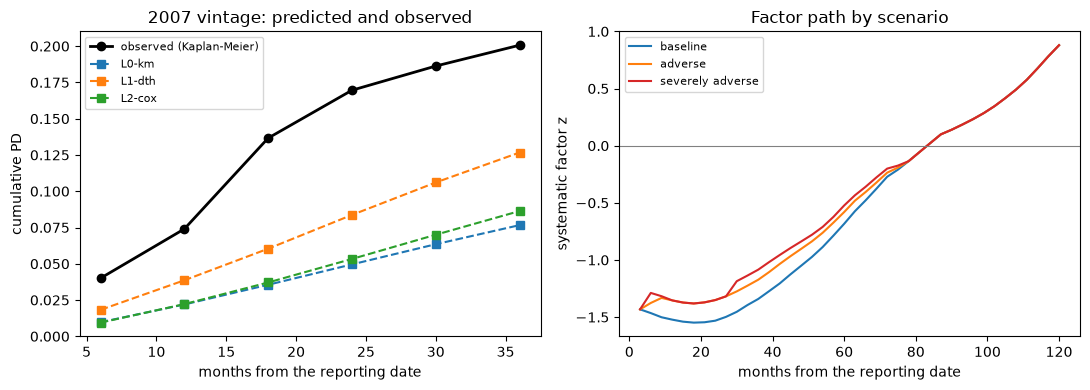

In [9]:
# Draw the crisis vintage against the three rungs and the factor paths of the three scenarios
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
months7, obs7, pred7 = curves["2007"]
left.plot(months7, obs7, color="black", marker="o", linewidth=2, label="observed (Kaplan-Meier)")
for rung, color in (("L0-km", "tab:blue"), ("L1-dth", "tab:orange"), ("L2-cox", "tab:green")):
    left.plot(months7, pred7[rung], color=color, marker="s", linestyle="--", label=rung)
left.set_xlabel("months from the reporting date")
left.set_ylabel("cumulative PD")
left.set_title("2007 vintage: predicted and observed")
left.legend(fontsize=8)

names = {"baseline": "baseline", "adverse": "adverse", "severely-adverse": "severely adverse"}
for sid, color in (("baseline", "tab:blue"), ("adverse", "tab:orange"), ("severely-adverse", "tab:red")):
    right.plot(months_path, paths[sid], color=color, label=names[sid])
right.axhline(0.0, color="grey", linewidth=0.8)
right.set_xlabel("months from the reporting date")
right.set_ylabel("systematic factor z")
right.set_title("Factor path by scenario")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The discrete-time logit and the Cox model agree closely, not identically.** On the 18 shared covariates the correlation of the coefficients is 0.9998 and the largest absolute difference is 0.0389 (accommodation and food, 0.6726 against 0.6336). The term effect, the strongest, is $-2.4475$ against $-2.4413$ for loans over 20 years. The largest difference is 3.2 standard errors of L1 (the revolving flag, 0.5083 against 0.5436): the two scales differ more where the period hazard is larger, as the approximation $\mathrm{logit}\,h \approx \log h$ says.
- **One macro sign is wrong.** Real GDP growth lowers the hazard as expected ($-0.1920$, $z = -49.11$, a hazard ratio of 0.825 per standard deviation) and the prime rate raises it (+0.1138, $z = +18.86$, 1.120). The unemployment rate lowers it ($-0.0534$, $z = -5.99$, 0.948), the opposite of the expected sign and statistically distinct from zero. This is the sensitivity the committed finding `F-SCENARIO-ORDER` blames for the severely adverse scenario giving a lower ECL than the baseline (notebook 03). A validator rejects a macro coefficient of the wrong sign even when it is significant, because a significant effect that moves against the economy can be a sign of collinearity among the macro variables over a short history (not tested here).
- **L1 wins every column of the comparison.** Its concordance is 0.6106 against 0.5903 for the Cox rung (the Kaplan-Meier rung reports none), its integrated Brier score is 0.0606 against 0.0615 for the other two (the three are within 0.001) and its 12-month calibration gap is 0.0025 against 0.0118 and 0.0141. A concordance near 0.6 is modest: the loan covariates rank loans only a little better than chance.
- **All three under-predict, and the crisis vintage most.** On the pooled cohort the observed cumulative default is 0.0324, 0.0804 and 0.1083 at 12, 24 and 36 months; L1 predicts 0.0298, 0.0637 and 0.0959, and L0 and L2 predict 0.0205, 0.0438, 0.0656 and 0.0183, 0.0416, 0.0656. At 36 months the signed gap is 0.0124 for L1 and 0.0427 for the other two. For the 2007 vintage the observed values are 0.0740, 0.1696 and 0.2006 and L1 predicts 0.0386, 0.0837 and 0.1267 (a gap of 0.0740 at 36 months), L0 0.0766 (0.1240) and L2 0.0863 (0.1143). The three rungs under-predict at every horizon in both cohorts. The macro covariates of L1 narrow the gap and do not close it.
- **Censoring against a competing exit.** The Kaplan-Meier baseline gives a cumulative default of 0.04394 at 36 months. With a stated prepayment hazard of 0.5%, 1% and 2% a quarter the default incidence is 0.04222, 0.04056 and 0.03744, so the censoring view is 4.1%, 8.3% and 17.4% above it at 36 months, and 9.2%, 19.2% and 41.1% above at 120 months. The longer the horizon, the more the choice matters; C06's lifetime ECL carries the censoring view.
- **The satellite has the expected signs, the paths revert, and the order is inverted.** The factor falls with unemployment ($-1.0554$) and the prime rate ($-1.4056$) and rises with growth (+0.3289). The history of the factor over 63 quarters has a mean of $-0.150$ and a standard deviation of 0.731, and ends at $-1.80$. The three scenario paths start at $-1.432$ and end at $+0.879$, which is the reversion to the long run. In between the baseline is below the adverse and the severely adverse (at month 42, $-1.205$, $-1.035$ and $-0.956$), the reverse of the expected severity order. In the hazard the unemployment rate lowers the PD; in the satellite it lowers the factor, which raises the PD: the two layers disagree on the sign, and the file does not say why.

What this notebook does not show: it reads the fits and does not refit them, because the raw loan file is not committed. The mixture cure, survival forest, deep survival, age-period-cohort and multistate methods of the state of the art are not run by the product, and whether any package for them is available is UNVERIFIED. The prepayment hazards are inputs of the lesson, not estimates, and the observed outcomes are charge-offs of SBA loans.

## Summary

- The three C06 rungs are the survival methods the research recommends at its simplest: the Kaplan-Meier curve, a discrete-time logit with macro covariates and a Cox model without time-varying covariates; the mixture cure, forest, deep and multistate methods are not run.
- The logit and the Cox coefficients agree closely on the common covariates, because the period hazard is small.
- The macro layer is where the rungs differ and where the model fails a validator's sign check: unemployment has the wrong sign in the hazard, which inverts the order of the scenarios.
- The hazard rung wins on discrimination, Brier score and 12-month calibration, but every rung under-predicts the cumulative PD at every horizon, and the crisis vintage most.
- Treating prepayment as censoring overstates the lifetime default incidence, by more at longer horizons; the macro paths revert to the long run as the ECB letter asks.

**What to try next.** Change `EXPECTED_SIGN` and see which coefficients fail; add a prepayment hazard of 3% to the competing-risks cell; read the same tables in the `models-rd-2020-06.json` file and compare the signs. Then continue with notebook 08, which demonstrates the claim of this topic.

## References

- Botha, A. and Verster, T. (2025), Approaches for modelling the term-structure of default risk under IFRS 9: a tutorial using discrete-time survival analysis, equations 6 to 10. https://arxiv.org/abs/2507.15441
- Botha, A., Verster, T. and Breedt, R. (2025), Modelling the term-structure of default risk under IFRS 9 within a multistate regression framework. https://arxiv.org/abs/2502.14479
- Shumway, T. (2001), Forecasting bankruptcy more accurately: a simple hazard model, Journal of Business 74(1), 101-124. https://doi.org/10.1086/209665
- Cox, D. R. (1972), Regression models and life-tables, Journal of the Royal Statistical Society B 34(2), 187-202. https://doi.org/10.1111/j.2517-6161.1972.tb00899.x
- Fine, J. P. and Gray, R. J. (1999), A proportional hazards model for the subdistribution of a competing risk, Journal of the American Statistical Association 94(446), 496-509. https://doi.org/10.1080/01621459.1999.10474144
- Breeden, J. L. (2016), Incorporating lifecycle and environment in loan-level forecasts and stress tests, European Journal of Operational Research 255(2), 649-658. https://doi.org/10.1016/j.ejor.2016.06.008
- ECB Banking Supervision (2020), IFRS 9 in the context of the coronavirus (COVID-19) pandemic, letter to banks of 1 April 2020: weights on short-term forecasts and reversion to long-term values. https://www.bankingsupervision.europa.eu/press/letterstobanks/shared/pdf/2020/ssm.2020_letter_IFRS_9_in_the_context_of_the_coronavirus_COVID-19_pandemic~4cab8e5650.en.pdf
- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm